# Weekly project
This weeks weekly project is a continuation of last weeks exercises.

You are to make a handwritten number classifier. Where we will be using the [mnist dataset](https://en.wikipedia.org/wiki/MNIST_database).

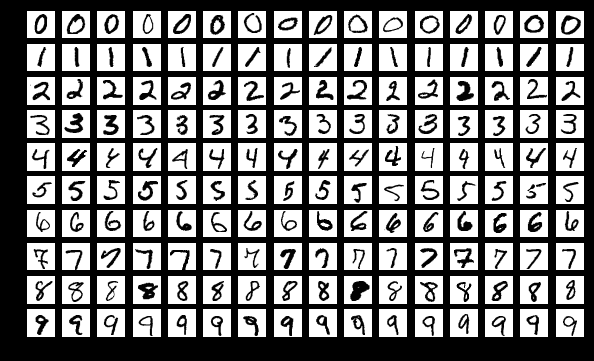

**Create a program that given an image from the mnist dataset.**
- You are free to use any algorithm you want to achieve this.
- It should be able to given a number classify what number it is.
- Accuracy should at least be 80%

If you decide to use a svm make sure you also use dimensionality reduction. SVM of the full mnist dataset will take around 4-8 hours depending on your pc.



**Challange:**
- Try to reach 98% accuracy.
- Try to classify faces with the labeled wild faces dataset [lwf](http://vis-www.cs.umass.edu/lfw/)
```{Python}
from sklearn.datasets import fetch_lfw_people
lfw_people = fetch_lfw_people(min_faces_per_person=70, resize=0.4)
```

In [10]:
import math

import matplotlib.pyplot as plt
import numpy as np
import time
import datetime as dt
from sklearn.decomposition import PCA
from sklearn import datasets, svm, metrics
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler

import ssl
ssl._create_default_https_context = ssl._create_unverified_context
mnist = fetch_openml('mnist_784', version=1)

images = mnist.data.to_numpy()
targets = mnist.target.to_numpy()

print(images.shape)
print(targets.shape)

(70000, 784)
(70000,)


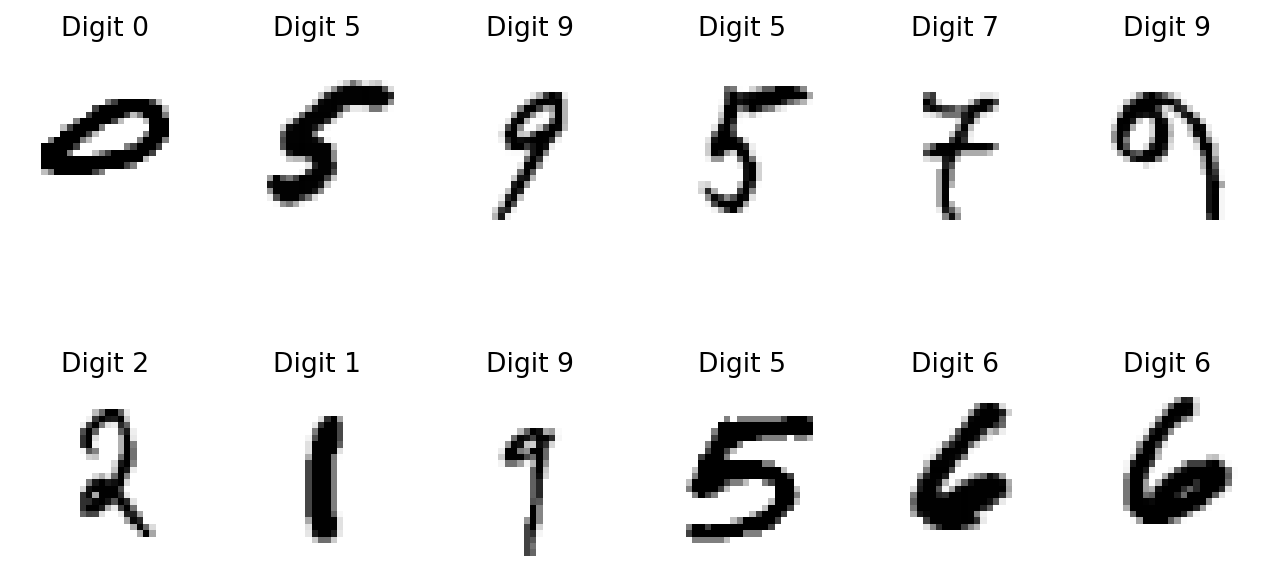

In [11]:
def show_some_digits(images, targets, sample_size=24, title_text='Digit {}' ):
    '''
    Visualize random digits in a grid plot
    images - array of flatten gidigs [:,784]
    targets - final labels
    '''
    nsamples=sample_size
    rand_idx = np.random.choice(images.shape[0], nsamples)
    images_and_labels = list(zip(images[rand_idx], targets[rand_idx]))


    img = plt.figure(1, figsize=(10, 5), dpi=160)
    for index, (image, label) in enumerate(images_and_labels):
        plt.subplot(math.ceil(nsamples/6.0), 6, index + 1)
        plt.axis('off')
        #each image is flat, we have to reshape to 2D array 28x28-784
        plt.imshow(image.reshape(28,28), cmap=plt.cm.gray_r, interpolation='nearest')
        plt.title(title_text.format(label))
    plt.show()

# draw 12 images along with their labels
show_some_digits(images, targets, 12)

In [22]:
#MNIST with SV
pca = PCA(n_components=40)
iamges = StandardScaler().fit_transform(images)

images_reduced = pca.fit_transform(images)

print(pca.explained_variance_ratio_)
print(sum(pca.explained_variance_ratio_))

[0.09746116 0.07155445 0.06149531 0.05403385 0.04888934 0.04305227
 0.03278262 0.02889642 0.02758364 0.0234214  0.02106689 0.02037553
 0.01707064 0.0169402  0.01583382 0.01486345 0.01319358 0.01279014
 0.01187272 0.01152937 0.0106604  0.01009794 0.00959151 0.00909635
 0.00883287 0.00838818 0.00809832 0.00785718 0.00740262 0.00690014
 0.00656144 0.0064547  0.00600819 0.00585612 0.00566754 0.00543471
 0.00504717 0.00487079 0.00478955 0.00467594]
0.7869984553331804


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(images_reduced, targets, test_size=0.2)
print(X_train.shape)
print(X_test.shape)

(56000, 40)
(14000, 40)


In [21]:
clf = svm.LinearSVC(penalty='l2', loss='squared_hinge', random_state=42, max_iter=10000)
clf.fit(X_train, y_train)

print(f'Train score {clf.score(X_train, y_train)}, Test score {clf.score(X_test, y_test)}')

Train score 0.8769642857142858, Test score 0.8732857142857143


In [31]:
import numpy as np
from tqdm.auto import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.datasets as datasets
from torch.utils.data import DataLoader
import torchvision.transforms as transforms

/opt/homebrew/Caskroom/miniforge/base/envs/pfas/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [32]:
device = None
if torch.backends.mps.is_available():
    print('MPS is available')
    device = torch.device('mps')
else:
    print("The code will run on CPU. Go to Edit->Notebook Settings and choose GPU as the hardware accelerator")
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

MPS is available
mps


In [ ]:
class Network(nn.Module):
    def __init__(self):
        super(Network, self).__init__()
        self.convolutional = nn.Sequential(
                nn.Conv2d(1, 8, (3,3), padding='same'),
                nn.ReLU(),
                nn.Conv2d(8, 8,(3,3), padding='same'),
                nn.ReLU(),
                nn.MaxPool2d((2,2)),
                nn.Conv2d(8, 16, (3,3), padding='same'),
                nn.ReLU(),
                nn.Conv2d(16, 16, (3,3), padding='same'),
                nn.ReLU(),
                )

        self.fully_connected = nn.Sequential(
                nn.Linear(14*14*16, 500),
                nn.ReLU(),
                nn.Linear(500, 10))
    
    def forward(self, x):
        x = self.convolutional(x)
        x = x.view(x.size(0), -1)
        x = self.fully_connected(x)
        return x

In [ ]:
X_cnn = images.reshape(-1, 1, 28, 28).astype('float32') / 255.0
y_cnn = targets.astype('int64')

X_train_cnn, X_test_cnn, y_train_cnn, y_test_cnn = train_test_split(
    X_cnn, y_cnn, test_size=0.2, random_state=42)

trainset = torch.utils.data.TensorDataset(
    torch.from_numpy(X_train_cnn), torch.from_numpy(y_train_cnn))
testset = torch.utils.data.TensorDataset(
    torch.from_numpy(X_test_cnn), torch.from_numpy(y_test_cnn))

batch_size = 64
train_loader = DataLoader(trainset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(testset, batch_size=batch_size, shuffle=False)

In [38]:
model = Network().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

n_epochs = 10
for epoch in range(n_epochs):
    start = time.time()
    model.train()
    train_loss = 0
    correct = 0
    for X_batch, y_batch in tqdm(train_loader):
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * X_batch.size(0)
        correct += (outputs.argmax(dim=1) == y_batch).sum().item()

    train_acc = correct / len(trainset)
    elapsed = time.time() - start
    print(f'Epoch {epoch+1}/{n_epochs}: {elapsed:.1f}s  loss={train_loss/len(trainset):.4f}  train_acc={train_acc:.4f}')


test_loss = 0
correct = 0
model.eval()
with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)

        test_loss += loss.item() * X_batch.size(0)
        correct += (outputs.argmax(dim=1) == y_batch).sum().item()

test_acc = correct / len(testset)
print(f"Test loss: {test_loss/len(testset):.4f}, accuracy: {test_acc:.4f}")

100%|██████████| 875/875 [00:07<00:00, 114.80it/s]


Epoch 1/10: 7.6s  loss=0.2293  train_acc=0.9267


100%|██████████| 875/875 [00:07<00:00, 116.48it/s]


Epoch 2/10: 7.5s  loss=0.0523  train_acc=0.9834


100%|██████████| 875/875 [00:07<00:00, 116.84it/s]


...

Epoch 8/10: 7.6s  loss=0.0093  train_acc=0.9971


100%|██████████| 875/875 [00:07<00:00, 122.13it/s]


Epoch 9/10: 7.2s  loss=0.0088  train_acc=0.9971


100%|██████████| 875/875 [00:07<00:00, 123.78it/s]


Epoch 10/10: 7.1s  loss=0.0064  train_acc=0.9979
Test loss: 0.0490, accuracy: 0.9881


In [39]:
from sklearn.datasets import fetch_lfw_people
lfw_people = fetch_lfw_people(min_faces_per_person=70, resize=0.4)

In [41]:
X = lfw_people.data
y = lfw_people.target

print(X.shape)

(1288, 1850)


Exception ignored in: <function tqdm.__del__ at 0x14f685990>
Traceback (most recent call last):
  File "/opt/homebrew/Caskroom/miniforge/base/envs/pfas/lib/python3.10/site-packages/tqdm/std.py", line 1154, in __del__
    self.close()
  File "/opt/homebrew/Caskroom/miniforge/base/envs/pfas/lib/python3.10/site-packages/tqdm/notebook.py", line 279, in close
    self.disp(bar_style='danger', check_delay=False)
AttributeError: 'tqdm_notebook' object has no attribute 'disp'


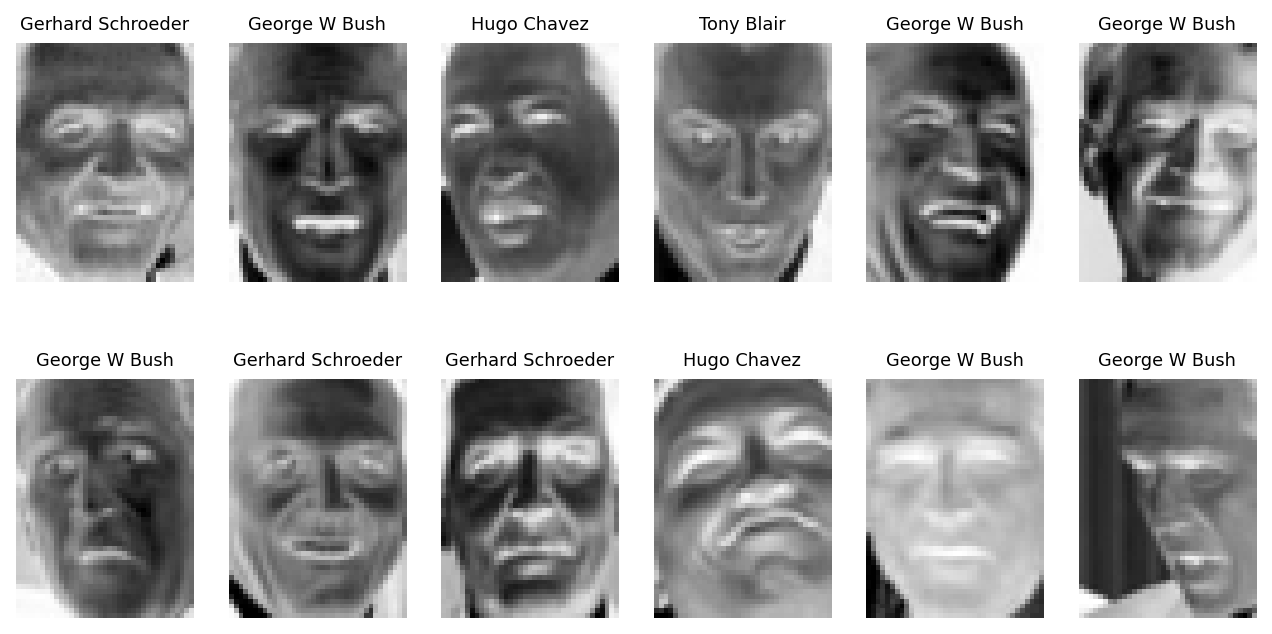

50 37


In [ ]:
def show_some_faces(images, targets, target_names, h, w, sample_size=24, title_text='{}'):
    '''
    Visualize random faces in a grid plot
    images - array of flattened faces [:, h*w]
    targets - integer class labels
    target_names - array mapping label index -> person name
    h, w - original (unflattened) image height/width
    '''
    nsamples = sample_size
    rand_idx = np.random.choice(images.shape[0], nsamples)
    images_and_labels = list(zip(images[rand_idx], targets[rand_idx]))

    plt.figure(1, figsize=(10, 5), dpi=160)
    for index, (image, label) in enumerate(images_and_labels):
        plt.subplot(math.ceil(nsamples/6.0), 6, index + 1)
        plt.axis('off')
        plt.imshow(image.reshape(h, w), cmap=plt.cm.gray_r, interpolation='nearest')
        plt.title(title_text.format(target_names[label]), fontsize=8)
    plt.show()

h, w = lfw_people.images.shape[1:]
show_some_faces(X, y, lfw_people.target_names, h, w, 12)

In [ ]:
h, w = lfw_people.images.shape[1:]
n_classes = len(lfw_people.target_names)

X_faces = X.reshape(-1, 1, h, w).astype('float32')
y_faces = y.astype('int64')

X_train_faces, X_test_faces, y_train_faces, y_test_faces = train_test_split(
    X_faces, y_faces, test_size=0.2, random_state=42, stratify=y_faces)

face_train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05)),
])

class FaceDataset(torch.utils.data.Dataset):
    def __init__(self, X, y, transform=None):
        self.X = X
        self.y = y
        self.transform = transform

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = self.X[idx]
        if self.transform is not None:
            x = self.transform(x)
        return x, self.y[idx]

face_trainset = FaceDataset(
    torch.from_numpy(X_train_faces), torch.from_numpy(y_train_faces),
    transform=face_train_transform)

face_testset = torch.utils.data.TensorDataset(
    torch.from_numpy(X_test_faces), torch.from_numpy(y_test_faces))

face_batch_size = 16
face_train_loader = DataLoader(face_trainset, batch_size=face_batch_size, shuffle=True)
face_test_loader = DataLoader(face_testset, batch_size=face_batch_size, shuffle=False)

In [68]:
class FaceNetwork(nn.Module):
    def __init__(self, h, w, n_classes):
        super(FaceNetwork, self).__init__()
        self.convolutional = nn.Sequential(
                nn.Conv2d(1, 8, (3,3), padding='same'),
                nn.BatchNorm2d(8),
                nn.ReLU(),
                nn.Conv2d(8, 8, (3,3), padding='same'),
                nn.BatchNorm2d(8),
                nn.ReLU(),
                nn.MaxPool2d((2,2)),
                nn.Conv2d(8, 16, (3,3), padding='same'),
                nn.BatchNorm2d(16),
                nn.ReLU(),
                nn.Conv2d(16, 32, (3,3), padding='same'),
                nn.BatchNorm2d(32),
                nn.ReLU(),
                )

        flat_dim = 32 * (h // 2) * (w // 2)
        self.fully_connected = nn.Sequential(
                nn.Linear(flat_dim, 500),
                nn.ReLU(),
                nn.Dropout(0.5),
                nn.Linear(500, n_classes))

    def forward(self, x):
        x = self.convolutional(x)
        x = x.view(x.size(0), -1)
        x = self.fully_connected(x)
        return x

In [70]:
face_model = FaceNetwork(h, w, n_classes).to(device)
face_optimizer = torch.optim.Adam(face_model.parameters(), lr=0.001, weight_decay=1e-4)
face_criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

n_epochs = 80
for epoch in range(n_epochs):
    start = time.time()
    face_model.train()
    train_loss = 0
    correct = 0
    for X_batch, y_batch in face_train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        face_optimizer.zero_grad()
        outputs = face_model(X_batch)
        loss = face_criterion(outputs, y_batch)
        loss.backward()
        face_optimizer.step()

        train_loss += loss.item() * X_batch.size(0)
        correct += (outputs.argmax(dim=1) == y_batch).sum().item()

    train_acc = correct / len(face_trainset)
    elapsed = time.time() - start
    print(f'Epoch {epoch+1}/{n_epochs}: {elapsed:.1f}s  loss={train_loss/len(face_trainset):.4f}  train_acc={train_acc:.4f}')


test_loss = 0
correct = 0
face_model.eval()
with torch.no_grad():
    for X_batch, y_batch in face_test_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        outputs = face_model(X_batch)
        loss = face_criterion(outputs, y_batch)

        test_loss += loss.item() * X_batch.size(0)
        correct += (outputs.argmax(dim=1) == y_batch).sum().item()

test_acc = correct / len(face_testset)
print(f"Test loss: {test_loss/len(face_testset):.4f}, accuracy: {test_acc:.4f}")

Epoch 1/80: 1.1s  loss=2.4386  train_acc=0.3388
Epoch 2/80: 1.3s  loss=1.6770  train_acc=0.4330
Epoch 3/80: 1.1s  loss=1.5227  train_acc=0.5126
Epoch 4/80: 1.1s  loss=1.4134  train_acc=0.5544
Epoch 5/80: 1.3s  loss=1.3399  train_acc=0.5971
Epoch 6/80: 1.1s  loss=1.3455  train_acc=0.5981
Epoch 7/80: 1.1s  loss=1.2580  train_acc=0.6311
Epoch 8/80: 1.1s  loss=1.2341  train_acc=0.6417
Epoch 9/80: 1.1s  loss=1.2084  train_acc=0.6485
Epoch 10/80: 1.1s  loss=1.1491  train_acc=0.6883
Epoch 11/80: 1.1s  loss=1.1262  train_acc=0.7097
Epoch 12/80: 1.1s  loss=1.0876  train_acc=0.7175
Epoch 13/80: 1.1s  loss=1.0485  train_acc=0.7427
Epoch 14/80: 1.1s  loss=1.0452  train_acc=0.7340
Epoch 15/80: 1.1s  loss=0.9962  train_acc=0.7738
Epoch 16/80: 1.1s  loss=1.0066  train_acc=0.7835
Epoch 17/80: 1.1s  loss=0.9595  train_acc=0.7845
Epoch 18/80: 1.1s  loss=0.9600  train_acc=0.7883
Epoch 19/80: 1.1s  loss=0.9233  train_acc=0.8039
Epoch 20/80: 1.1s  loss=0.9361  train_acc=0.7961
Epoch 21/80: 1.1s  loss=0.925